<a href="https://colab.research.google.com/github/anamaciel149/DL_cibernetico/blob/main/TRAB_PSP8_DL_Phishing_PhiUSIIL_FINAL_Colab_VSCode.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Detecção de Phishing por Deep Learning com a base PhiUSIIL

**MVP reprodutível - compatível com Google Colab e VS Code/Jupyter**

Objetivo: classificar URLs como **legítimas** ou **phishing** usando uma DNN sobre atributos lexicais da URL.

Decisão metodológica importante: o experimento usa apenas atributos que podem ser derivados da própria URL, evitando campos de identificação e atributos de conteúdo da página que podem criar atalhos artificiais ou exigir o carregamento da página antes da decisão.

In [1]:
# 0. Ambiente e dependências
import sys, subprocess, importlib.util, os
from pathlib import Path

IS_COLAB = 'google.colab' in sys.modules
print('Ambiente:', 'Google Colab' if IS_COLAB else 'VS Code/Jupyter local')
print('Python:', sys.version.split()[0])

required = {
    'numpy':'numpy', 'pandas':'pandas', 'matplotlib':'matplotlib', 'sklearn':'scikit-learn',
    'tensorflow':'tensorflow', 'ucimlrepo':'ucimlrepo', 'joblib':'joblib'
}
missing=[pip for mod,pip in required.items() if importlib.util.find_spec(mod) is None]
if missing:
    print('Instalando:', missing)
    subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
else:
    print('Dependências já disponíveis.')

Ambiente: Google Colab
Python: 3.13.18
Instalando: ['ucimlrepo']


In [2]:
# 1. Imports e reprodutibilidade
import json, random, math, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, classification_report,
    RocCurveDisplay, PrecisionRecallDisplay
)
import joblib

SEED=42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

OUT = Path('artefatos_phiusiil')
OUT.mkdir(exist_ok=True)
print('TensorFlow:', tf.__version__)

TensorFlow: 2.21.0


## 2. Perguntas do MVP

1. Como se distribuem URLs legítimas e de phishing?
2. Há problemas de qualidade, duplicidade ou valores não finitos?
3. Quais atributos podem ser usados sem depender do conteúdo da página?
4. Uma DNN consegue separar phishing de URLs legítimas usando somente atributos lexicais?
5. Qual o desempenho em acurácia, precisão, recall, F1, ROC-AUC e PR-AUC?
6. Qual limiar equilibra melhor precisão e recall no conjunto de validação?
7. Quantos sites de phishing escapam do detector e quantos legítimos geram falso alarme?

In [3]:
# 3. Aquisição - UCI Machine Learning Repository, dataset id 967
phi = fetch_ucirepo(id=967)
X_raw = phi.data.features.copy()
y_raw = phi.data.targets.copy()

print('X:', X_raw.shape)
print('y:', y_raw.shape)
display(X_raw.head())
display(y_raw.head())

X: (235795, 54)
y: (235795, 1)


,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,...,1,0,0,1,34,20,28,119,0,124
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,...,0,0,0,1,50,9,8,39,0,217
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,...,0,0,0,1,10,2,7,42,2,5
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,...,0,1,1,1,3,27,15,22,1,31
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,...,1,1,0,1,244,15,34,72,1,85


,label
0,1
1,1
2,1
3,1
4,1


In [4]:
# 4. Normalização do rótulo
# Na base original: 1 = legítima, 0 = phishing.
# No MVP, padronizamos a classe positiva: 1 = phishing, 0 = legítima.
label_col = y_raw.columns[0]
y = (1 - pd.to_numeric(y_raw[label_col], errors='coerce')).astype('Int64')

base = X_raw.copy()
base['target_phishing'] = y
base = base.dropna(subset=['target_phishing']).copy()
base['target_phishing'] = base['target_phishing'].astype(int)

print(base['target_phishing'].value_counts().rename(index={0:'Legítima (0)',1:'Phishing (1)'}))
print(base['target_phishing'].value_counts(normalize=True).mul(100).round(2))

target_phishing
Legítima (0)    134850
Phishing (1)    100945
Name: count, dtype: int64
target_phishing
0    57.19
1    42.81
Name: proportion, dtype: float64


In [5]:
# 5. Seleção de atributos lexicais / disponíveis antes do clique
LEXICAL_FEATURES = [
    'URLLength','DomainLength','IsDomainIP','TLDLength','NoOfSubDomain',
    'HasObfuscation','NoOfObfuscatedChar','ObfuscationRatio',
    'NoOfLettersInURL','LetterRatioInURL','NoOfDegitsInURL','DegitRatioInURL',
    'NoOfEqualsInURL','NoOfQMarkInURL','NoOfAmpersandInURL',
    'NoOfOtherSpecialCharsInURL','SpacialCharRatioInURL','IsHTTPS'
]

missing_features=[c for c in LEXICAL_FEATURES if c not in base.columns]
if missing_features:
    raise KeyError(f'Colunas esperadas não encontradas: {missing_features}')

X = base[LEXICAL_FEATURES].copy()
y = base['target_phishing'].copy()

# Converte qualquer valor inesperado para numérico.
for c in X.columns:
    X[c] = pd.to_numeric(X[c], errors='coerce')
X = X.replace([np.inf,-np.inf], np.nan)

print('Atributos usados:', len(LEXICAL_FEATURES))
print(LEXICAL_FEATURES)

Atributos usados: 18
['URLLength', 'DomainLength', 'IsDomainIP', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS']


In [6]:
# 6. Qualidade dos dados
quality = pd.DataFrame({
    'dtype': X.dtypes.astype(str),
    'nulos': X.isna().sum(),
    'unicos': X.nunique(dropna=True),
    'min': X.min(numeric_only=True),
    'max': X.max(numeric_only=True)
})
print('Duplicatas exatas em X+y:', pd.concat([X,y],axis=1).duplicated().sum())
display(quality)
quality.to_csv(OUT/'qualidade_dados.csv', encoding='utf-8-sig')

Duplicatas exatas em X+y: 203022


,dtype,nulos,unicos,min,max
URLLength,int64,0,482,13.0,6097.000
DomainLength,int64,0,101,4.0,110.000
IsDomainIP,int64,0,2,0.0,1.000
TLDLength,int64,0,12,2.0,13.000
NoOfSubDomain,int64,0,10,0.0,10.000
HasObfuscation,int64,0,2,0.0,1.000
NoOfObfuscatedChar,int64,0,20,0.0,447.000
ObfuscationRatio,float64,0,146,0.0,0.348
NoOfLettersInURL,int64,0,421,0.0,5191.000
LetterRatioInURL,float64,0,709,0.0,0.926


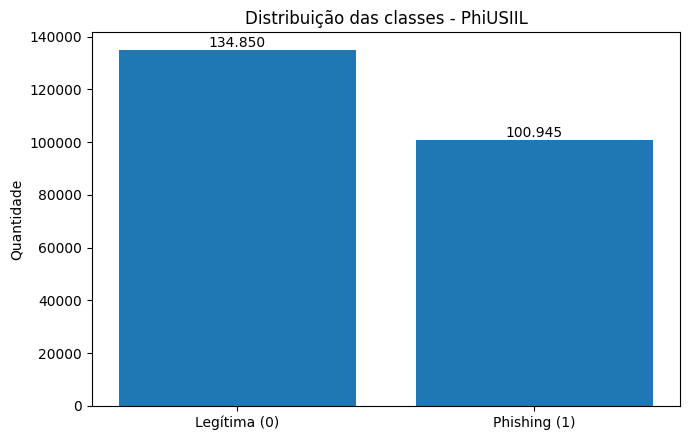

In [7]:
# 7. Distribuição das classes
counts = y.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7,4.5))
ax.bar(['Legítima (0)','Phishing (1)'], [counts.get(0,0), counts.get(1,0)])
ax.set_title('Distribuição das classes - PhiUSIIL')
ax.set_ylabel('Quantidade')
for i,v in enumerate([counts.get(0,0), counts.get(1,0)]): ax.text(i,v,f'{v:,}'.replace(',', '.'),ha='center',va='bottom')
fig.tight_layout(); fig.savefig(OUT/'distribuicao_classes.png',dpi=180,bbox_inches='tight'); plt.show()

In [8]:
# 8. Split estratificado 70/15/15
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)

print('Treino:', X_train_raw.shape, y_train.value_counts().to_dict())
print('Validação:', X_val_raw.shape, y_val.value_counts().to_dict())
print('Teste:', X_test_raw.shape, y_test.value_counts().to_dict())

Treino: (165056, 18) {0: 94395, 1: 70661}
Validação: (35369, 18) {0: 20227, 1: 15142}
Teste: (35370, 18) {0: 20228, 1: 15142}


In [9]:
# 9. Pré-processamento: mediana + padronização
prep = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
X_train = prep.fit_transform(X_train_raw).astype(np.float32)
X_val = prep.transform(X_val_raw).astype(np.float32)
X_test = prep.transform(X_test_raw).astype(np.float32)
joblib.dump(prep, OUT/'preprocessador.joblib')
print(X_train.shape, X_val.shape, X_test.shape)

(165056, 18) (35369, 18) (35370, 18)


## 10. DNN
Arquitetura em funil: **18 atributos → Dense 128 → Dense 64 → Dense 32 → Sigmoid**.

- ReLU nas camadas ocultas;
- Batch Normalization;
- Dropout 0,30 / 0,30 / 0,20;
- Adam e Binary Cross-Entropy;
- class weights;
- Early Stopping e ReduceLROnPlateau.

In [10]:
# 10. Modelo
classes = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weight = {int(c): float(w) for c,w in zip(classes,weights)}
print('Class weights:', class_weight)

model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(), layers.Dropout(0.30),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(), layers.Dropout(0.30),
    layers.Dense(32, activation='relu'), layers.Dropout(0.20),
    layers.Dense(1, activation='sigmoid')
])
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.Precision(name='precision'), keras.metrics.Recall(name='recall'), keras.metrics.AUC(name='auc')]
)
model.summary()

Class weights: {0: 0.8742835955294243, 1: 1.167942712387314}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,569 (53.00 KB)

 Trainable params: 13,185 (51.50 KB)

 Non-trainable params: 384 (1.50 KB)

In [11]:
# 11. Treinamento
callbacks=[
    keras.callbacks.EarlyStopping(monitor='val_loss',patience=4,restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss',factor=0.5,patience=2,min_lr=1e-5)
]
history = model.fit(
    X_train, y_train.to_numpy(),
    validation_data=(X_val,y_val.to_numpy()),
    epochs=30,batch_size=256,class_weight=class_weight,callbacks=callbacks,verbose=1
)
model.save(OUT/'modelo_dnn_phiusiil.keras')
pd.DataFrame(history.history).to_csv(OUT/'historico_treinamento.csv',index=False)

Epoch 1/30
645/645 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9884 - auc: 0.9973 - loss: 0.0425 - precision: 0.9861 - recall: 0.9868 - val_accuracy: 0.9964 - val_auc: 0.9981 - val_loss: 0.0181 - val_precision: 0.9998 - val_recall: 0.9917 - learning_rate: 0.0010
Epoch 2/30
645/645 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9960 - auc: 0.9978 - loss: 0.0224 - precision: 0.9985 - recall: 0.9922 - val_accuracy: 0.9967 - val_auc: 0.9982 - val_loss: 0.0169 - val_precision: 0.9999 - val_recall: 0.9923 - learning_rate: 0.0010
Epoch 3/30
645/645 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9964 - auc: 0.9979 - loss: 0.0204 - precision: 0.9989 - recall: 0.9928 - val_accuracy: 0.9969 - val_auc: 0.9984 - val_loss: 0.0158 - val_precision: 0.9999 - val_recall: 0.9928 - learning_rate: 0.0010
Epoch 4/30
645/645 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9967 - auc: 0.9981 - loss: 0.0194 - precision: 0.9990 - recall: 0.9932 - val_accuracy: 0.9970 - val_auc: 0.9985 - val_loss: 0.0154 - va

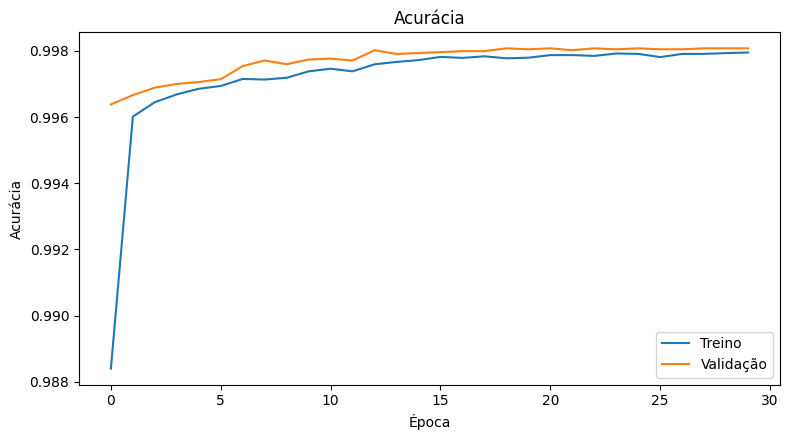

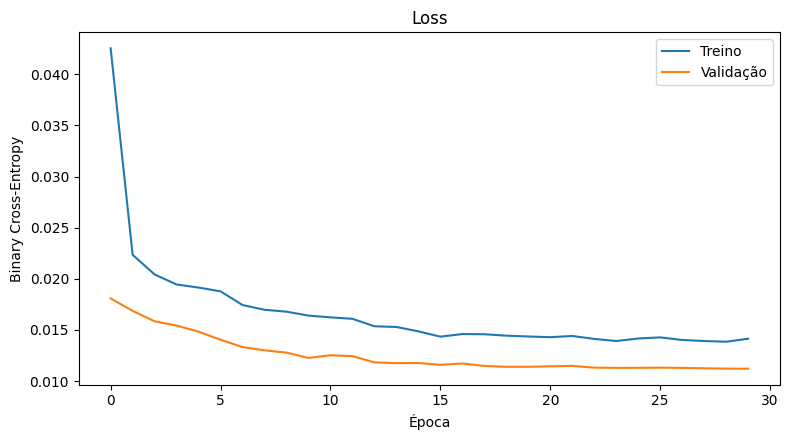

In [12]:
# 12. Curvas de treinamento
hist=pd.DataFrame(history.history)
fig,ax=plt.subplots(figsize=(8,4.5)); ax.plot(hist.index,hist['accuracy'],label='Treino'); ax.plot(hist.index,hist['val_accuracy'],label='Validação'); ax.set_title('Acurácia'); ax.set_xlabel('Época'); ax.set_ylabel('Acurácia'); ax.legend(); fig.tight_layout(); fig.savefig(OUT/'curva_acuracia.png',dpi=180,bbox_inches='tight'); plt.show()
fig,ax=plt.subplots(figsize=(8,4.5)); ax.plot(hist.index,hist['loss'],label='Treino'); ax.plot(hist.index,hist['val_loss'],label='Validação'); ax.set_title('Loss'); ax.set_xlabel('Época'); ax.set_ylabel('Binary Cross-Entropy'); ax.legend(); fig.tight_layout(); fig.savefig(OUT/'curva_loss.png',dpi=180,bbox_inches='tight'); plt.show()

Threshold escolhido: 0.24 F1 validação: 0.9978493200542633


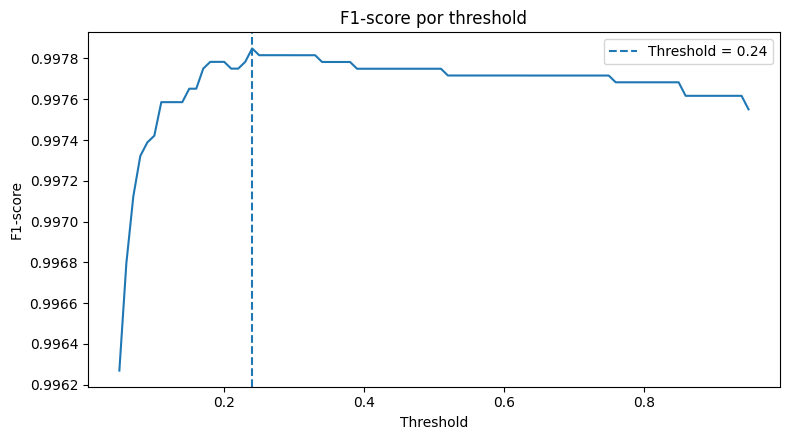

In [13]:
# 13. Escolha do threshold usando SOMENTE validação
val_score = model.predict(X_val, verbose=0).ravel()
thresholds = np.round(np.arange(0.05,0.951,0.01),2)
f1s=[]
for t in thresholds:
    f1s.append(f1_score(y_val,(val_score>=t).astype(int),zero_division=0))
best_idx=int(np.argmax(f1s)); best_threshold=float(thresholds[best_idx])
print('Threshold escolhido:', best_threshold, 'F1 validação:', f1s[best_idx])
fig,ax=plt.subplots(figsize=(8,4.5)); ax.plot(thresholds,f1s); ax.axvline(best_threshold,ls='--',label=f'Threshold = {best_threshold:.2f}'); ax.set_title('F1-score por threshold'); ax.set_xlabel('Threshold'); ax.set_ylabel('F1-score'); ax.legend(); fig.tight_layout(); fig.savefig(OUT/'f1_por_threshold.png',dpi=180,bbox_inches='tight'); plt.show()

In [14]:
# 14. Avaliação FINAL no teste isolado
score = model.predict(X_test, verbose=0).ravel()
pred = (score >= best_threshold).astype(int)

acc=accuracy_score(y_test,pred)
prec=precision_score(y_test,pred,zero_division=0)
rec=recall_score(y_test,pred,zero_division=0)
f1=f1_score(y_test,pred,zero_division=0)
roc=roc_auc_score(y_test,score)
ap=average_precision_score(y_test,score)
tn,fp,fn,tp=confusion_matrix(y_test,pred,labels=[0,1]).ravel()
fpr=fp/(fp+tn); fnr=fn/(fn+tp)

metrics={
    'accuracy':acc,'precision':prec,'recall':rec,'f1':f1,'roc_auc':roc,'pr_auc':ap,
    'threshold':best_threshold,'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp),
    'false_positive_rate':fpr,'false_negative_rate':fnr,
    'test_size':int(len(y_test)),'test_phishing':int((y_test==1).sum()),'test_legitimate':int((y_test==0).sum())
}
print(json.dumps(metrics,indent=2,ensure_ascii=False))
print(classification_report(y_test,pred,target_names=['Legítima','Phishing'],digits=4))
pd.DataFrame([metrics]).to_csv(OUT/'metricas_modelo.csv',index=False)

{
  "accuracy": 0.9983319197059655,
  "precision": 0.9998011796673073,
  "recall": 0.9963016774534408,
  "f1": 0.9980483609539876,
  "roc_auc": 0.9989906898629433,
  "pr_auc": 0.9991985893920723,
  "threshold": 0.24,
  "tn": 20225,
  "fp": 3,
  "fn": 56,
  "tp": 15086,
  "false_positive_rate": 0.00014830927427328456,
  "false_negative_rate": 0.0036983225465592393,
  "test_size": 35370,
  "test_phishing": 15142,
  "test_legitimate": 20228
}
              precision    recall  f1-score   support

    Legítima     0.9972    0.9999    0.9985     20228
    Phishing     0.9998    0.9963    0.9980     15142

    accuracy                         0.9983     35370
   macro avg     0.9985    0.9981    0.9983     35370
weighted avg     0.9983    0.9983    0.9983     35370



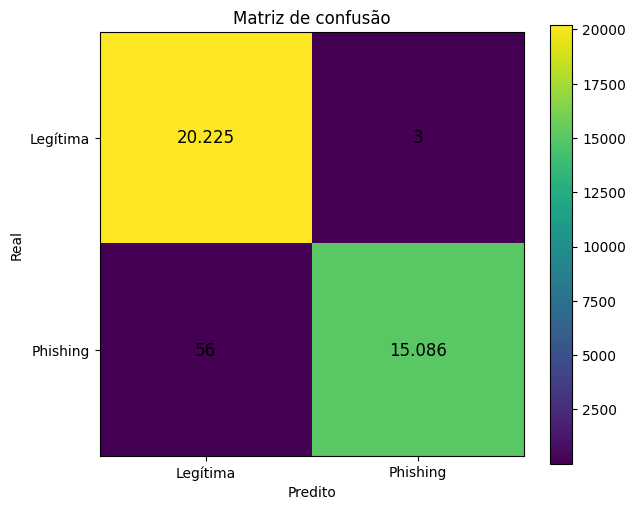

In [15]:
# 15. Matriz de confusão
cm=np.array([[tn,fp],[fn,tp]])
fig,ax=plt.subplots(figsize=(6.5,5.3))
im=ax.imshow(cm)
ax.set_xticks([0,1],['Legítima','Phishing']); ax.set_yticks([0,1],['Legítima','Phishing'])
ax.set_xlabel('Predito'); ax.set_ylabel('Real'); ax.set_title('Matriz de confusão')
for i in range(2):
    for j in range(2): ax.text(j,i,f'{cm[i,j]:,}'.replace(',','.'),ha='center',va='center',fontsize=12)
fig.colorbar(im,ax=ax); fig.tight_layout(); fig.savefig(OUT/'matriz_confusao.png',dpi=180,bbox_inches='tight'); plt.show()

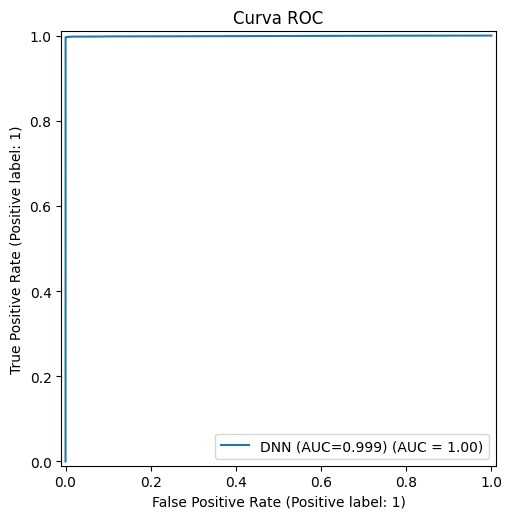

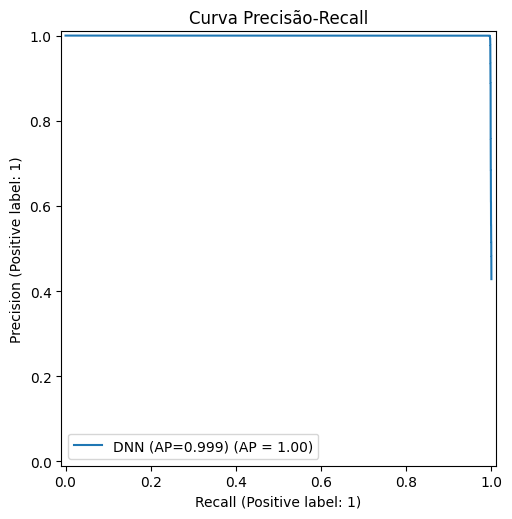

In [16]:
# 16. ROC e Precision-Recall
fig,ax=plt.subplots(figsize=(6.5,5.3)); RocCurveDisplay.from_predictions(y_test,score,ax=ax,name=f'DNN (AUC={roc:.3f})'); ax.set_title('Curva ROC'); fig.tight_layout(); fig.savefig(OUT/'curva_roc.png',dpi=180,bbox_inches='tight'); plt.show()
fig,ax=plt.subplots(figsize=(6.5,5.3)); PrecisionRecallDisplay.from_predictions(y_test,score,ax=ax,name=f'DNN (AP={ap:.3f})'); ax.set_title('Curva Precisão-Recall'); fig.tight_layout(); fig.savefig(OUT/'curva_precision_recall.png',dpi=180,bbox_inches='tight'); plt.show()

In [17]:
# 17. Arquivo LaTeX com resultados - copiar para paper/slides no Overleaf
pct = lambda x: f'{100*x:.2f}'.replace('.', ',') + r'\%'
num = lambda x: f'{int(x):,}'.replace(',', '.')
thr_txt = f'{best_threshold:.2f}'.replace('.', ',')

tex = '% Arquivo gerado automaticamente pelo notebook\n\n'
tex += f'\\renewcommand{{\\Accuracy}}{{{pct(acc)}}}\n'
tex += f'\\renewcommand{{\\PrecisionMetric}}{{{pct(prec)}}}\n'
tex += f'\\renewcommand{{\\RecallMetric}}{{{pct(rec)}}}\n'
tex += f'\\renewcommand{{\\FOne}}{{{pct(f1)}}}\n'
tex += f'\\renewcommand{{\\ROCAUC}}{{{pct(roc)}}}\n'
tex += f'\\renewcommand{{\\PRAUC}}{{{pct(ap)}}}\n'
tex += f'\\renewcommand{{\\Threshold}}{{{thr_txt}}}\n'
tex += f'\\renewcommand{{\\TN}}{{{num(tn)}}}\n'
tex += f'\\renewcommand{{\\FP}}{{{num(fp)}}}\n'
tex += f'\\renewcommand{{\\FN}}{{{num(fn)}}}\n'
tex += f'\\renewcommand{{\\TP}}{{{num(tp)}}}\n'
tex += f'\\renewcommand{{\\FPR}}{{{pct(fpr)}}}\n'
tex += f'\\renewcommand{{\\FNR}}{{{pct(fnr)}}}\n'
tex += f'\\renewcommand{{\\TestPhishing}}{{{num((y_test == 1).sum())}}}\n'
tex += f'\\renewcommand{{\\TestLegit}}{{{num((y_test == 0).sum())}}}\n'

(OUT / 'resultados_latex.tex').write_text(tex, encoding='utf-8')
print(tex)


% Arquivo gerado automaticamente pelo notebook

\renewcommand{\Accuracy}{99,83\%}
\renewcommand{\PrecisionMetric}{99,98\%}
\renewcommand{\RecallMetric}{99,63\%}
\renewcommand{\FOne}{99,80\%}
\renewcommand{\ROCAUC}{99,90\%}
\renewcommand{\PRAUC}{99,92\%}
\renewcommand{\Threshold}{0,24}
\renewcommand{\TN}{20.225}
\renewcommand{\FP}{3}
\renewcommand{\FN}{56}
\renewcommand{\TP}{15.086}
\renewcommand{\FPR}{0,01\%}
\renewcommand{\FNR}{0,37\%}
\renewcommand{\TestPhishing}{15.142}
\renewcommand{\TestLegit}{20.228}



In [18]:
# 18. Resumo executivo e checklist
summary = (
    f"RESULTADOS - DNN / PhiUSIIL\n"
    f"Threshold: {best_threshold:.2f}\n"
    f"Acurácia: {acc:.4f}\n"
    f"Precisão: {prec:.4f}\n"
    f"Recall: {rec:.4f}\n"
    f"F1-score: {f1:.4f}\n"
    f"ROC-AUC: {roc:.4f}\n"
    f"PR-AUC: {ap:.4f}\n"
    f"TN={tn} FP={fp} FN={fn} TP={tp}\n"
    f"FPR={fpr:.4f} FNR={fnr:.4f}\n"
)
(OUT / 'resumo_resultados.txt').write_text(summary, encoding='utf-8')
print(summary)
print('Artefatos salvos em:', OUT.resolve())

# 19. Sincronização opcional com as pastas do projeto (quando notebook roda na raiz do ZIP)
project_root = Path.cwd()
for sub in ['paper', 'slides']:
    dest = project_root / sub
    if dest.exists():
        shutil.copy2(OUT / 'resultados_latex.tex', dest / 'resultados.tex')
        img_dest = dest / 'images'
        img_dest.mkdir(exist_ok=True)
        for name in [
            'distribuicao_classes.png', 'curva_acuracia.png', 'curva_loss.png',
            'f1_por_threshold.png', 'matriz_confusao.png', 'curva_roc.png',
            'curva_precision_recall.png'
        ]:
            src_img = OUT / name
            if src_img.exists():
                shutil.copy2(src_img, img_dest / name)
        print(f'Paper/slides atualizados automaticamente em: {dest}')

# ZIP com os artefatos gerados, útil para baixar do Colab
shutil.make_archive('artefatos_phiusiil', 'zip', OUT)
print('ZIP de artefatos:', (project_root / 'artefatos_phiusiil.zip').resolve())


RESULTADOS - DNN / PhiUSIIL
Threshold: 0.24
Acurácia: 0.9983
Precisão: 0.9998
Recall: 0.9963
F1-score: 0.9980
ROC-AUC: 0.9990
PR-AUC: 0.9992
TN=20225 FP=3 FN=56 TP=15086
FPR=0.0001 FNR=0.0037

Artefatos salvos em: /content/artefatos_phiusiil
ZIP de artefatos: /content/artefatos_phiusiil.zip
